In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("public_transport_delays.csv")

# Display first 5 rows
df.head()

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1


In [2]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Total records
print("Total Rows:", df.shape[0])

# Total features
print("Total Columns:", df.shape[1])

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (2000, 24)
Total Rows: 2000
Total Columns: 24

Column Names:
['trip_id', 'date', 'time', 'transport_type', 'route_id', 'origin_station', 'destination_station', 'scheduled_departure', 'scheduled_arrival', 'actual_departure_delay_min', 'actual_arrival_delay_min', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'delayed']


In [3]:
# Check data types
print("DATA TYPES")
print(df.dtypes)

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:",
      df.isnull().sum().sum())

DATA TYPES
trip_id                        object
date                           object
time                           object
transport_type                 object
route_id                       object
origin_station                 object
destination_station            object
scheduled_departure            object
scheduled_arrival              object
actual_departure_delay_min      int64
actual_arrival_delay_min        int64
weather_condition              object
temperature_C                 float64
humidity_percent                int64
wind_speed_kmh                  int64
precipitation_mm              float64
event_type                     object
event_attendance_est            int64
traffic_congestion_index        int64
holiday                         int64
peak_hour                       int64
weekday                         int64
season                         object
delayed                         int64
dtype: object

MISSING VALUES
trip_id                          0
date        

In [4]:
# Check duplicate records
print("Duplicate Rows:", df.duplicated().sum())

# Check duplicate trip IDs
print("Duplicate Trip IDs:", df["trip_id"].duplicated().sum())

Duplicate Rows: 0
Duplicate Trip IDs: 0


In [5]:
# Target variable
target = "actual_arrival_delay_min"

# Statistical information
print("Target Variable Analysis")
print(df[target].describe())

# Check unique delay values
print("\nUnique Values:", df[target].nunique())

# Check minimum and maximum delay
print("\nMinimum Delay:", df[target].min())
print("Maximum Delay:", df[target].max())

# Check missing values
print("\nMissing Values:", df[target].isnull().sum())

Target Variable Analysis
count    2000.000000
mean       13.318000
std         9.289727
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64

Unique Values: 33

Minimum Delay: -3
Maximum Delay: 29

Missing Values: 0


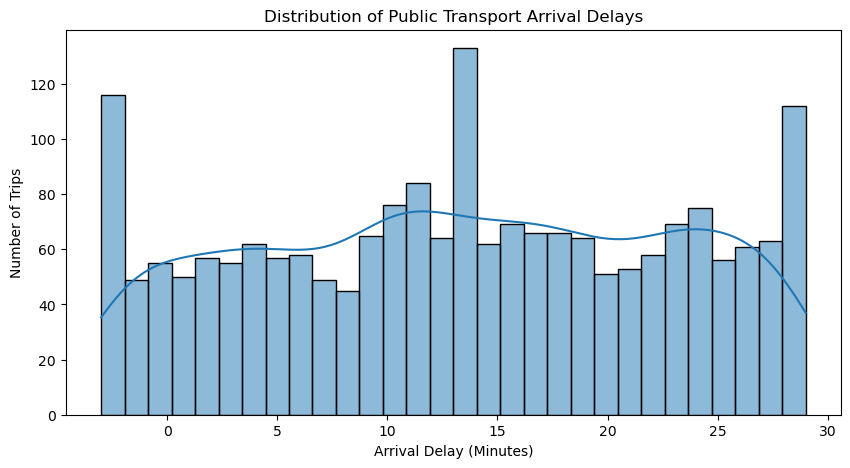

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df[target].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Public Transport Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Trips")

plt.show()

In [7]:
# Average delay by weather condition

weather_analysis = df.groupby(
    "weather_condition"
)["actual_arrival_delay_min"].mean().sort_values(
    ascending=False
)

print(weather_analysis)

weather_condition
Rain      13.623053
Snow      13.533528
Clear     13.501458
Storm     13.287834
Cloudy    13.073846
Fog       12.879154
Name: actual_arrival_delay_min, dtype: float64


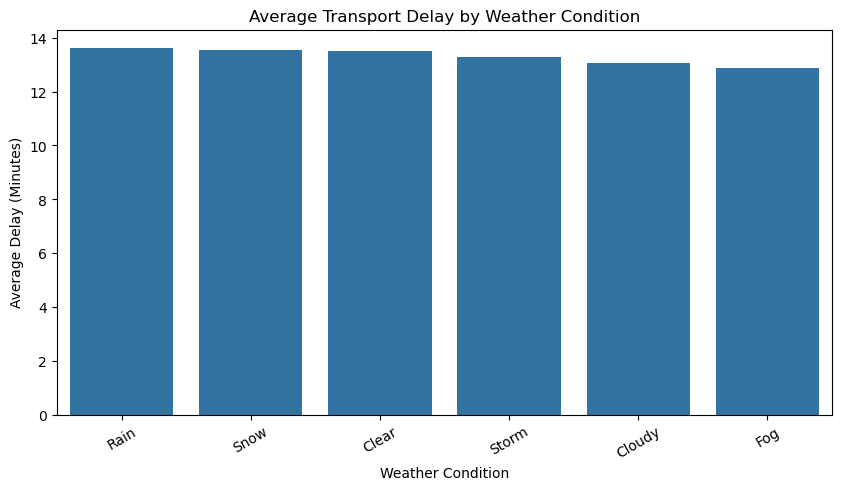

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weather_analysis.index,
    y=weather_analysis.values
)

plt.title("Average Transport Delay by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [9]:
event_analysis = df.groupby(
    "event_type"
)["actual_arrival_delay_min"].agg(
    ["mean", "median", "count"]
).sort_values(
    by="mean",
    ascending=False
)

print(event_analysis)

                 mean  median  count
event_type                          
Protest     13.895349    13.0     86
Parade      13.619048    14.0    105
Concert     12.832512    13.0    203
Sports      12.820755    13.0    212
Festival    12.769231    13.0    221


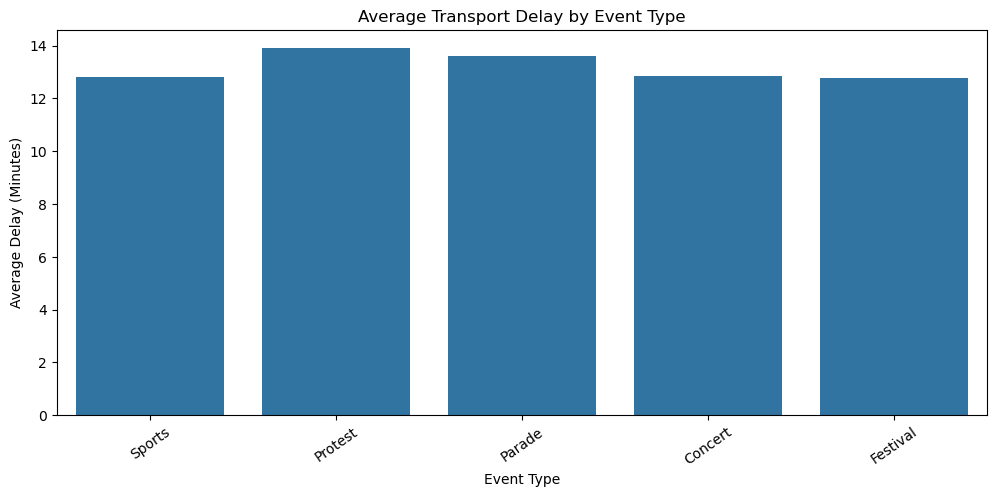

In [10]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x="event_type",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Event Type")
plt.xlabel("Event Type")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=35)

plt.show()

In [11]:
# Average delay by traffic congestion

traffic_analysis = df.groupby(
    "traffic_congestion_index"
)["actual_arrival_delay_min"].mean()

print(traffic_analysis)

traffic_congestion_index
0     14.894737
1     13.714286
2     13.173913
3     12.913043
4     14.260870
        ...    
95    13.400000
96    12.000000
97    16.857143
98    10.176471
99    11.428571
Name: actual_arrival_delay_min, Length: 100, dtype: float64


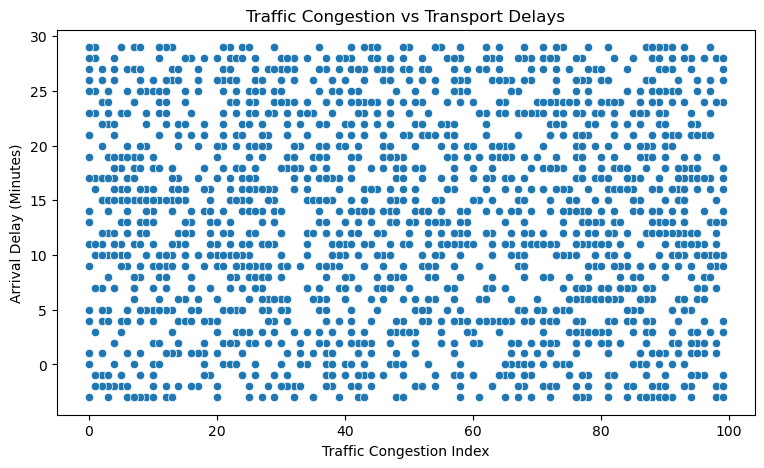

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="traffic_congestion_index",
    y="actual_arrival_delay_min"
)

plt.title("Traffic Congestion vs Transport Delays")
plt.xlabel("Traffic Congestion Index")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()

In [13]:
# Average delay during peak and non-peak hours

peak_analysis = df.groupby("peak_hour")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"])

print(peak_analysis)

                mean  median  count
peak_hour                          
0          13.302198    13.0   1456
1          13.360294    14.0    544


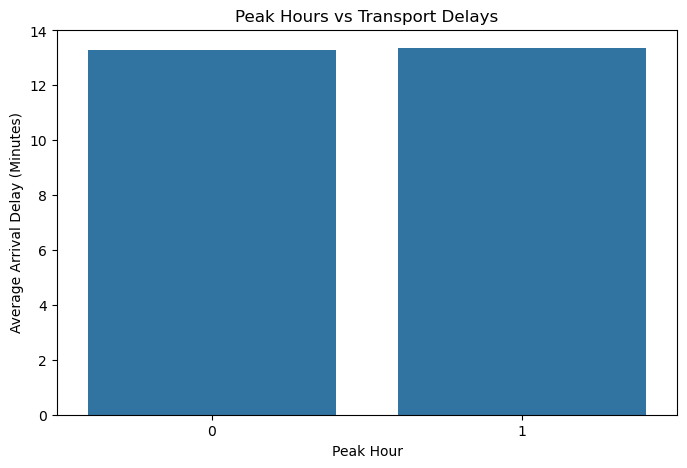

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="peak_hour",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Peak Hours vs Transport Delays")
plt.xlabel("Peak Hour")
plt.ylabel("Average Arrival Delay (Minutes)")

plt.show()

In [15]:
# Average delay by weekday

weekday_analysis = df.groupby("weekday")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"]).sort_values(
    by="mean",
    ascending=False
)

print(weekday_analysis)

              mean  median  count
weekday                          
4        14.305556    15.0    288
0        14.041667    14.0    288
5        13.732639    14.5    288
1        13.118056    13.0    288
2        12.888889    13.0    288
6        12.797794    12.0    272
3        12.312500    12.0    288


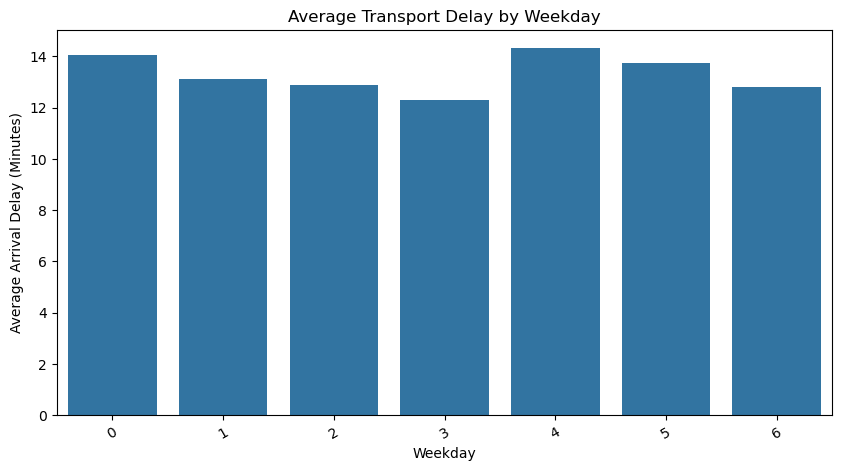

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weekday",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [17]:
weekday_analysis = df.groupby("weekday")[
    "actual_arrival_delay_min"
].agg(["mean", "median", "count"]).sort_values(
    by="mean", ascending=False
)

print(weekday_analysis)

              mean  median  count
weekday                          
4        14.305556    15.0    288
0        14.041667    14.0    288
5        13.732639    14.5    288
1        13.118056    13.0    288
2        12.888889    13.0    288
6        12.797794    12.0    272
3        12.312500    12.0    288


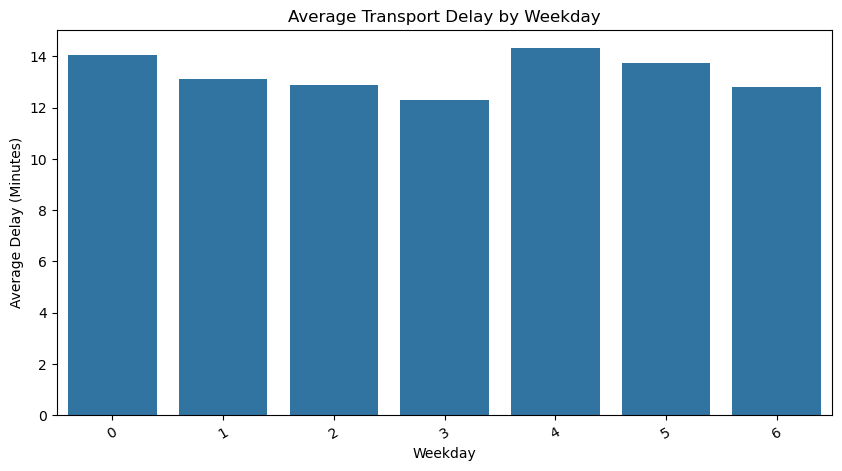

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="weekday",
    y="actual_arrival_delay_min",
    errorbar=None
)

plt.title("Average Transport Delay by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=30)

plt.show()

In [19]:
temperature_analysis = df.groupby(
    pd.cut(df["temperature_C"], bins=5)
)["actual_arrival_delay_min"].mean()

print(temperature_analysis)

temperature_C
(-5.04, 3.0]    13.859375
(3.0, 11.0]     13.235714
(11.0, 19.0]    13.466334
(19.0, 27.0]    13.481865
(27.0, 35.0]    12.594132
Name: actual_arrival_delay_min, dtype: float64


C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_25212\3713428725.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temperature_analysis = df.groupby(


In [20]:
rain_analysis = df.groupby(
    pd.cut(df["precipitation_mm"], bins=5),
    observed=True
)["actual_arrival_delay_min"].mean()

print(rain_analysis)

precipitation_mm
(-0.02, 4.0]    13.461722
(4.0, 8.0]      13.645933
(8.0, 12.0]     12.276923
(12.0, 16.0]    13.573604
(16.0, 20.0]    13.602632
Name: actual_arrival_delay_min, dtype: float64


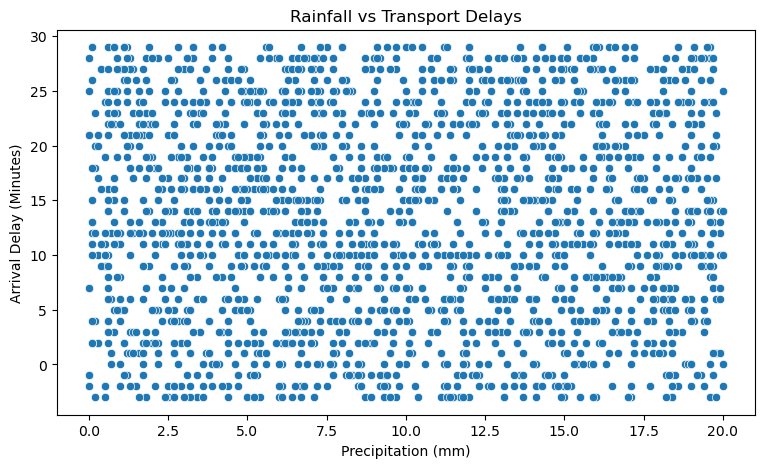

In [21]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="precipitation_mm",
    y="actual_arrival_delay_min"
)

plt.title("Rainfall vs Transport Delays")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Arrival Delay (Minutes)")

plt.show()

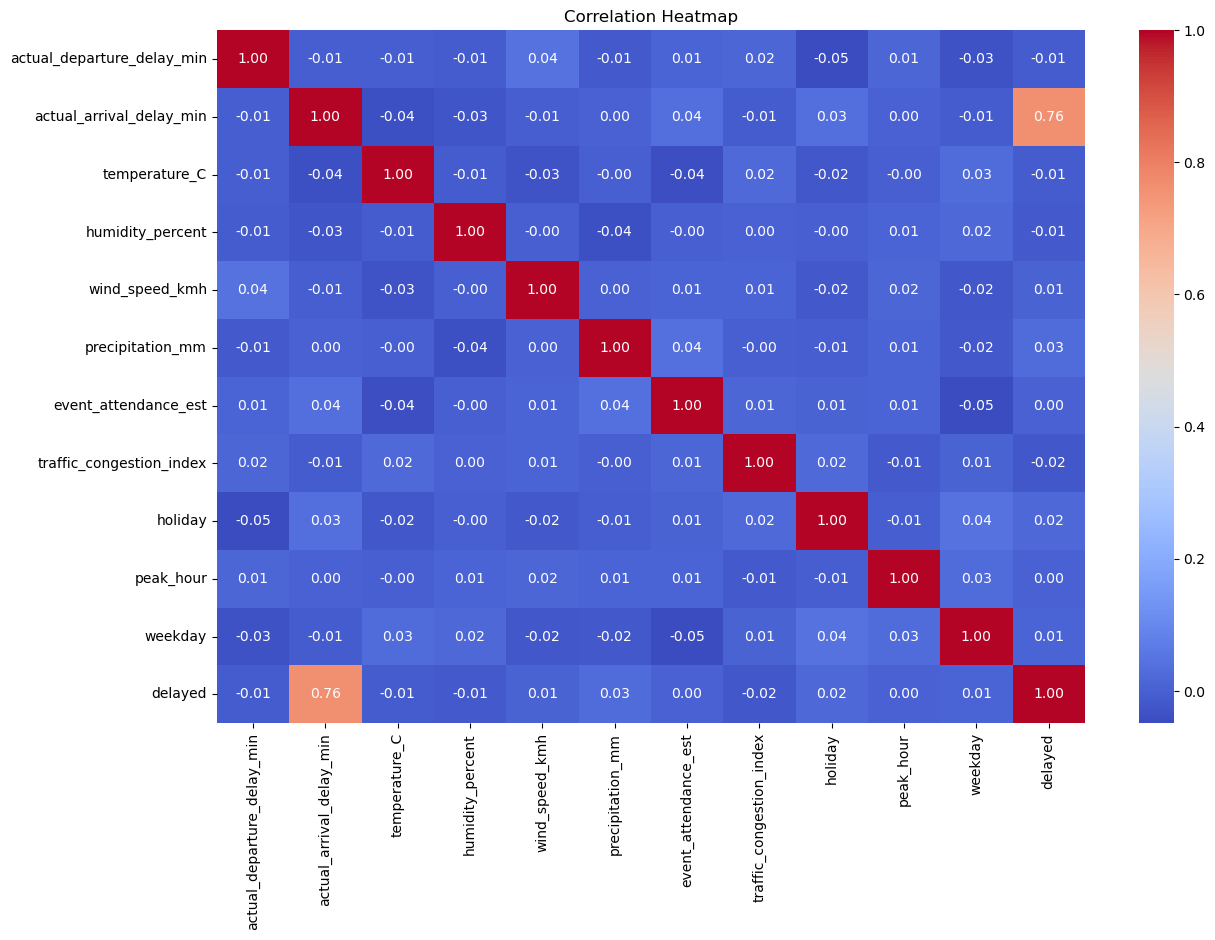

In [22]:
plt.figure(figsize=(14, 9))

correlation = df.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [23]:
target_corr = correlation[
    "actual_arrival_delay_min"
].sort_values(ascending=False)

print(target_corr)

actual_arrival_delay_min      1.000000
delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
precipitation_mm              0.001106
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
humidity_percent             -0.027705
temperature_C                -0.039944
Name: actual_arrival_delay_min, dtype: float64


In [24]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Missing Values:")
print(missing)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
event_type    1173
dtype: int64

Total Missing Values: 1173


In [25]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate trip IDs:", df["trip_id"].duplicated().sum())

Duplicate rows: 0
Duplicate trip IDs: 0


In [26]:
print(df.dtypes)

trip_id                        object
date                           object
time                           object
transport_type                 object
route_id                       object
origin_station                 object
destination_station            object
scheduled_departure            object
scheduled_arrival              object
actual_departure_delay_min      int64
actual_arrival_delay_min        int64
weather_condition              object
temperature_C                 float64
humidity_percent                int64
wind_speed_kmh                  int64
precipitation_mm              float64
event_type                     object
event_attendance_est            int64
traffic_congestion_index        int64
holiday                         int64
peak_hour                       int64
weekday                         int64
season                         object
delayed                         int64
dtype: object


In [27]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["scheduled_departure"] = pd.to_datetime(
    df["scheduled_departure"], errors="coerce"
)

df["scheduled_arrival"] = pd.to_datetime(
    df["scheduled_arrival"], errors="coerce"
)

print(df.dtypes)

C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_25212\1498974737.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["scheduled_departure"] = pd.to_datetime(
C:\Users\Vedant Patil\AppData\Local\Temp\ipykernel_25212\1498974737.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["scheduled_arrival"] = pd.to_datetime(


trip_id                               object
date                          datetime64[ns]
time                                  object
transport_type                        object
route_id                              object
origin_station                        object
destination_station                   object
scheduled_departure           datetime64[ns]
scheduled_arrival             datetime64[ns]
actual_departure_delay_min             int64
actual_arrival_delay_min               int64
weather_condition                     object
temperature_C                        float64
humidity_percent                       int64
wind_speed_kmh                         int64
precipitation_mm                     float64
event_type                            object
event_attendance_est                   int64
traffic_congestion_index               int64
holiday                                int64
peak_hour                              int64
weekday                                int64
season    

In [28]:
print(df["scheduled_departure"].head())
print(df["scheduled_arrival"].head())

0   2026-11-03 05:02:00
1   2026-11-03 05:16:00
2   2026-11-03 05:33:00
3   2026-11-03 05:49:00
4   2026-11-03 06:00:00
Name: scheduled_departure, dtype: datetime64[ns]
0   2026-11-03 05:55:00
1   2026-11-03 05:55:00
2   2026-11-03 06:17:00
3   2026-11-03 06:08:00
4   2026-11-03 06:35:00
Name: scheduled_arrival, dtype: datetime64[ns]


In [29]:
print("Invalid dates:", df["date"].isna().sum())

print("Invalid departures:",
      df["scheduled_departure"].isna().sum())

print("Invalid arrivals:",
      df["scheduled_arrival"].isna().sum())

Invalid dates: 0
Invalid departures: 0
Invalid arrivals: 0


In [30]:
df.to_csv(
    "public_transport_delays_cleaned.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [31]:
df["departure_hour"] = df["scheduled_departure"].dt.hour

df["departure_day"] = df["date"].dt.day

df["departure_month"] = df["date"].dt.month

df["is_weekend"] = (
    df["date"].dt.dayofweek >= 5
).astype(int)

print(df[[
    "scheduled_departure",
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend"
]].head(10))

  scheduled_departure  departure_hour  departure_day  departure_month  \
0 2026-11-03 05:02:00               5              1                1   
1 2026-11-03 05:16:00               5              1                1   
2 2026-11-03 05:33:00               5              1                1   
3 2026-11-03 05:49:00               5              1                1   
4 2026-11-03 06:00:00               6              1                1   
5 2026-11-03 06:15:00               6              1                1   
6 2026-11-03 06:34:00               6              1                1   
7 2026-11-03 06:47:00               6              1                1   
8 2026-11-03 07:01:00               7              1                1   
9 2026-11-03 07:17:00               7              1                1   

   is_weekend  
0           1  
1           1  
2           1  
3           1  
4           1  
5           1  
6           1  
7           1  
8           1  
9           1  


In [32]:
def classify_rush_hour(hour):

    if 7 <= hour <= 10:
        return "Morning Rush"

    elif 17 <= hour <= 20:
        return "Evening Rush"

    else:
        return "Non-Rush"


df["rush_hour_category"] = df["departure_hour"].apply(
    classify_rush_hour
)

print(df["rush_hour_category"].value_counts())

rush_hour_category
Non-Rush        1328
Morning Rush     336
Evening Rush     336
Name: count, dtype: int64


In [33]:
print(df[[
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend",
    "rush_hour_category"
]].head(10))

   departure_hour  departure_day  departure_month  is_weekend  \
0               5              1                1           1   
1               5              1                1           1   
2               5              1                1           1   
3               5              1                1           1   
4               6              1                1           1   
5               6              1                1           1   
6               6              1                1           1   
7               6              1                1           1   
8               7              1                1           1   
9               7              1                1           1   

  rush_hour_category  
0           Non-Rush  
1           Non-Rush  
2           Non-Rush  
3           Non-Rush  
4           Non-Rush  
5           Non-Rush  
6           Non-Rush  
7           Non-Rush  
8       Morning Rush  
9       Morning Rush  


In [34]:
rush_analysis = df.groupby(
    "rush_hour_category"
)["actual_arrival_delay_min"].agg(
    ["mean", "median", "count"]
)

print(rush_analysis)

                         mean  median  count
rush_hour_category                          
Evening Rush        12.952381    13.0    336
Morning Rush        13.845238    14.0    336
Non-Rush            13.277108    13.0   1328


In [35]:
# Define target variable
target = "actual_arrival_delay_min"

# Columns we should exclude
drop_columns = [
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
    "delayed"
]

# Separate features and target
X = df.drop(columns=drop_columns)

y = df[target]

# Display results
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Features shape: (2000, 21)
Target shape: (2000,)

Feature columns:
['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_type', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'season', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend', 'rush_hour_category']

Target variable:
actual_arrival_delay_min


In [36]:
# Identify categorical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify numerical columns
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nTotal categorical:", len(categorical_features))
print("Total numerical:", len(numerical_features))

Categorical Features:
['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season', 'rush_hour_category']

Numerical Features:
['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend']

Total categorical: 8
Total numerical: 13


In [37]:
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

print("Unique dates:", df["date"].nunique())

First date: 2023-01-01 00:00:00
Last date: 2023-01-22 00:00:00
Unique dates: 22


In [38]:
# Sort records chronologically
df_sorted = df.sort_values("date").copy()

# 80% training, 20% testing
split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index]
test_df = df_sorted.iloc[split_index:]

# Separate features and target
X_train = train_df[X.columns]
X_test = test_df[X.columns]

y_train = train_df[target]
y_test = test_df[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [40]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [41]:
y_pred_linear = linear_model.predict(X_test)

print("Actual values:", y_test.head(10).values)

print("\nPredicted values:", y_pred_linear[:10])

Actual values: [27  4 21 16 10 -3 -2 28 10  0]

Predicted values: [11.71080924 14.31384918 16.59599431 11.51581367 12.63461707 11.52232404
 14.76366611 13.58368213 11.93904333 13.45886172]


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred_linear)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2 = r2_score(y_test, y_pred_linear)

print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 8.418
RMSE: 9.78
R2 Score: -0.06


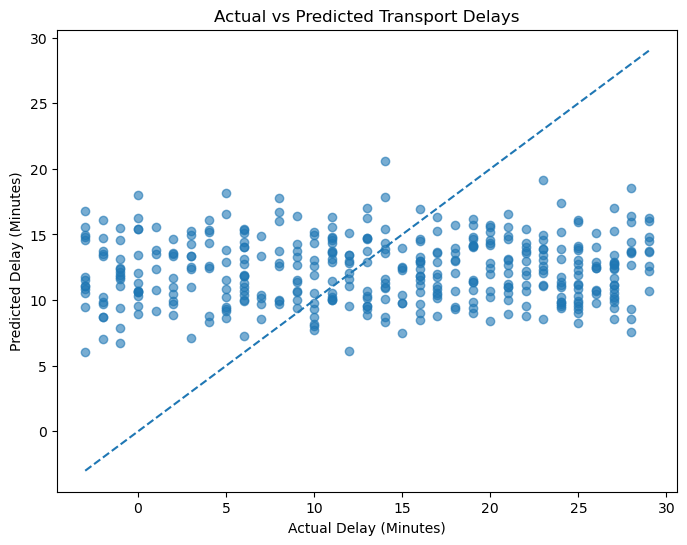

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Delay (Minutes)")
plt.ylabel("Predicted Delay (Minutes)")
plt.title("Actual vs Predicted Transport Delays")

plt.show()

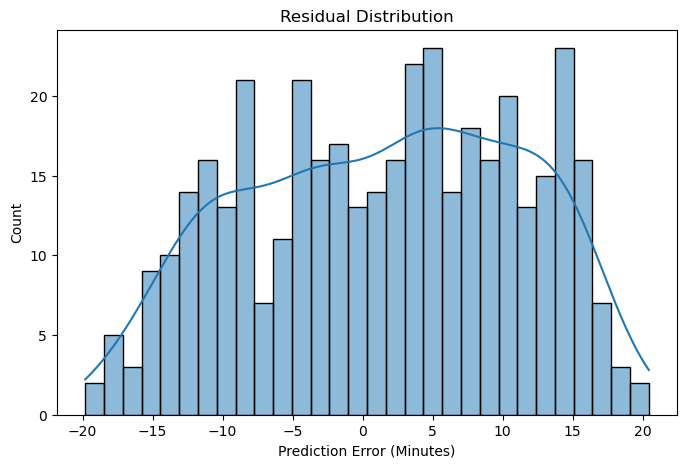

In [44]:
residuals = y_test - y_pred_linear

plt.figure(figsize=(8, 5))

sns.histplot(residuals, bins=30, kde=True)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error (Minutes)")
plt.show()

In [45]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [47]:
# Generate Random Forest predictions

y_pred_rf = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("Actual values:", y_test.head(10).values)
print("Predicted values:", y_pred_rf[:10])

Predictions generated successfully!
Actual values: [27  4 21 16 10 -3 -2 28 10  0]
Predicted values: [12.86803616 14.01164187 12.26623303 12.49963517 12.83379012 14.70255308
 13.67250969 12.60149335 13.08074568 13.13177144]


In [48]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("RANDOM FOREST PERFORMANCE")
print("--------------------------")
print("MAE:", round(mae_rf, 3))
print("RMSE:", round(rmse_rf, 3))
print("R2 Score:", round(r2_rf, 3))

RANDOM FOREST PERFORMANCE
--------------------------
MAE: 8.227
RMSE: 9.532
R2 Score: -0.007


In [50]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 21.4 MB/s eta 0:00:03
   - -------------------------------------- 2.4/48.9 MB 12.1 MB/s eta 0:00:04
   -- ------------------------------------- 3.1/48.9 MB 7.0 MB/s eta 0:00:07
   --- ------------------------------------ 4.5/48.9 MB 6.3 MB/s eta 0:00:08
   ---- ----------------------------------- 5.2/48.9 MB 6.0 MB/s eta 0:00:08
   ----- ---------------------------------- 6.3/48.9 MB 5.5 MB/s eta 0:00:08
   ------ --------------------------------- 7.6/48.9 MB 5.9 MB/s eta 0:00:08
   ------ --------------------------------- 8.4/48.9 MB 5.4 MB/s eta 0:00:08
   ------- -------------------------------- 8.9/48.9 MB 5.0 MB/s eta 0:00:09
   ------- -------------------------------- 9.4/48.9 MB 4.7 MB/s eta 0:00:09
   -------- ------------------------------- 10.0/48.9 MB 4.6 MB/s eta 0:00:09
   -------

In [51]:
from xgboost import XGBRegressor

print("XGBoost installed successfully!")

XGBoost installed successfully!


In [52]:
from xgboost import XGBRegressor

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        objective="reg:squarederror"
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [53]:
y_pred_xgb = xgb_model.predict(X_test)

print("Actual:", y_test.head(10).values)
print("Predicted:", y_pred_xgb[:10])

Actual: [27  4 21 16 10 -3 -2 28 10  0]
Predicted: [12.664968 14.781757 15.560923 12.569046 10.219308 13.870145 14.176814
 12.839012 12.621655 13.451469]


In [54]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBOOST PERFORMANCE")
print("--------------------")
print("MAE:", round(mae_xgb, 3))
print("RMSE:", round(rmse_xgb, 3))
print("R2 Score:", round(r2_xgb, 3))

XGBOOST PERFORMANCE
--------------------
MAE: 8.263
RMSE: 9.569
R2 Score: -0.015


               Model       MAE      RMSE  R2 Score
0  Linear Regression  8.418188  9.779578 -0.060336
1      Random Forest  8.227377  9.532134 -0.007357
2            XGBoost  8.263261  9.568815 -0.015125


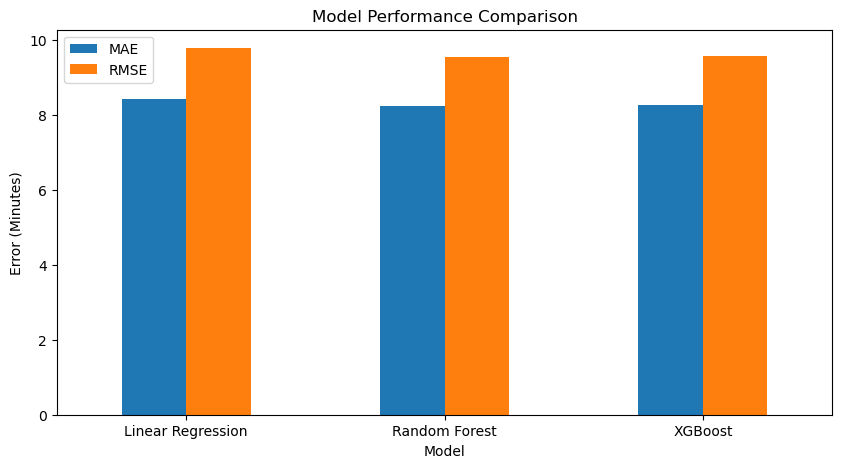

In [55]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [mae, mae_rf, mae_xgb],
    "RMSE": [rmse, rmse_rf, rmse_xgb],
    "R2 Score": [r2, r2_rf, r2_xgb]
})

print(results)

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error (Minutes)")
plt.xticks(rotation=0)
plt.show()

In [56]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MAE:",
      mean_absolute_error(y_test, baseline_predictions))

print("BASELINE R2:",
      r2_score(y_test, baseline_predictions))

BASELINE MAE: 8.212256250000001
BASELINE R2: -0.002594449182478753


In [57]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("BASELINE MAE:",
      mean_absolute_error(y_test, baseline_predictions))

print("BASELINE R2:",
      r2_score(y_test, baseline_predictions))

BASELINE MAE: 8.212256250000001
BASELINE R2: -0.002594449182478753


In [58]:
print("TRAINING TARGET STATISTICS")
print(y_train.describe())

print("\nTESTING TARGET STATISTICS")
print(y_test.describe())

print("\nTRAINING MEAN:", y_train.mean())
print("TESTING MEAN:", y_test.mean())

print("\nTRAINING STANDARD DEVIATION:", y_train.std())
print("TESTING STANDARD DEVIATION:", y_test.std())

TRAINING TARGET STATISTICS
count    1600.000000
mean       13.221250
std         9.234546
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64

TESTING TARGET STATISTICS
count    400.000000
mean      13.705000
std        9.509155
min       -3.000000
25%        6.000000
50%       14.000000
75%       22.000000
max       29.000000
Name: actual_arrival_delay_min, dtype: float64

TRAINING MEAN: 13.22125
TESTING MEAN: 13.705

TRAINING STANDARD DEVIATION: 9.234546359542609
TESTING STANDARD DEVIATION: 9.509155329876524


In [59]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "Baseline": baseline_predictions
})

print(comparison.mean().round(2))

Actual               13.70
Linear Regression    12.27
Random Forest        12.91
XGBoost              12.80
Baseline             13.22
dtype: float64


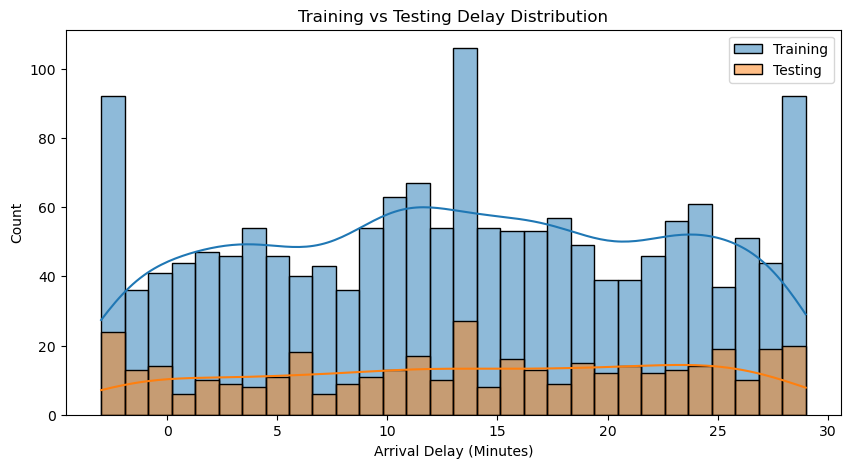

In [60]:
plt.figure(figsize=(10, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True,
    label="Training",
    alpha=0.5
)

sns.histplot(
    y_test,
    bins=30,
    kde=True,
    label="Testing",
    alpha=0.5
)

plt.title("Training vs Testing Delay Distribution")
plt.xlabel("Arrival Delay (Minutes)")
plt.legend()
plt.show()

In [61]:
numeric_corr = df.select_dtypes(
    include="number"
).corr()

target_relationship = numeric_corr[
    "actual_arrival_delay_min"
].drop("actual_arrival_delay_min").sort_values(
    ascending=False
)

print(target_relationship)

delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
departure_day                 0.001659
precipitation_mm              0.001106
is_weekend                   -0.002647
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
departure_hour               -0.017650
humidity_percent             -0.027705
temperature_C                -0.039944
departure_month                    NaN
Name: actual_arrival_delay_min, dtype: float64


In [62]:
print(
    df[[
        "actual_departure_delay_min",
        "actual_arrival_delay_min"
    ]].corr()
)

                            actual_departure_delay_min  \
actual_departure_delay_min                    1.000000   
actual_arrival_delay_min                     -0.007161   

                            actual_arrival_delay_min  
actual_departure_delay_min                 -0.007161  
actual_arrival_delay_min                    1.000000  


In [63]:
print(
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
)

actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64


In [64]:
# Reconstruct scheduled timestamps using the actual date

df["scheduled_departure"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d") + " " +
    df["scheduled_departure"].dt.strftime("%H:%M:%S")
)

df["scheduled_arrival"] = pd.to_datetime(
    df["date"].dt.strftime("%Y-%m-%d") + " " +
    df["scheduled_arrival"].dt.strftime("%H:%M:%S")
)

print(df[[
    "date",
    "scheduled_departure",
    "scheduled_arrival"
]].head())

        date scheduled_departure   scheduled_arrival
0 2023-01-01 2023-01-01 05:02:00 2023-01-01 05:55:00
1 2023-01-01 2023-01-01 05:16:00 2023-01-01 05:55:00
2 2023-01-01 2023-01-01 05:33:00 2023-01-01 06:17:00
3 2023-01-01 2023-01-01 05:49:00 2023-01-01 06:08:00
4 2023-01-01 2023-01-01 06:00:00 2023-01-01 06:35:00


In [65]:
# Recreate time-based features

df["departure_hour"] = df["scheduled_departure"].dt.hour

df["departure_day"] = df["date"].dt.day

df["departure_month"] = df["date"].dt.month

df["is_weekend"] = (
    df["date"].dt.dayofweek >= 5
).astype(int)

print(df[[
    "date",
    "departure_hour",
    "departure_day",
    "departure_month",
    "is_weekend"
]].head())

        date  departure_hour  departure_day  departure_month  is_weekend
0 2023-01-01               5              1                1           1
1 2023-01-01               5              1                1           1
2 2023-01-01               5              1                1           1
3 2023-01-01               5              1                1           1
4 2023-01-01               6              1                1           1


In [66]:
def classify_rush_hour(hour):
    if 7 <= hour <= 10:
        return "Morning Rush"
    elif 17 <= hour <= 20:
        return "Evening Rush"
    else:
        return "Non-Rush"

df["rush_hour_category"] = df[
    "departure_hour"
].apply(classify_rush_hour)

print(df["rush_hour_category"].value_counts())

rush_hour_category
Non-Rush        1328
Morning Rush     336
Evening Rush     336
Name: count, dtype: int64


In [67]:
df.to_csv(
    "public_transport_delays_cleaned.csv",
    index=False
)

print("Corrected dataset saved!")

Corrected dataset saved!


In [68]:
# Define target
target = "actual_arrival_delay_min"

# Remove identifiers and unavailable prediction-time variables
drop_columns = [
    "trip_id",
    "date",
    "time",
    "scheduled_departure",
    "scheduled_arrival",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
    "delayed"
]

X = df.drop(columns=drop_columns)
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (2000, 21)
Target: (2000,)


In [69]:
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)


Categorical: ['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season', 'rush_hour_category']
Numerical: ['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'departure_hour', 'departure_day', 'departure_month', 'is_weekend']


In [70]:
df_sorted = df.sort_values("date").copy()

split_index = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_index]
test_df = df_sorted.iloc[split_index:]

X_train = train_df[X.columns]
X_test = test_df[X.columns]

y_train = train_df[target]
y_test = test_df[target]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1600, 21)
Testing: (400, 21)


In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline rebuilt successfully!")

Preprocessing pipeline rebuilt successfully!


In [72]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Corrected Random Forest trained!")

Corrected Random Forest trained!


In [73]:
y_pred_rf = rf_model.predict(X_test)

print("Actual:", y_test.head(10).values)
print("Predicted:", y_pred_rf[:10])

Actual: [27  4 21 16 10 -3 -2 28 10  0]
Predicted: [13.06499297 13.91478481 12.85787049 12.49695892 12.4355072  14.84459531
 13.71608971 12.76627736 12.99355782 12.8034763 ]


In [74]:
mae_rf_corrected = mean_absolute_error(
    y_test, y_pred_rf
)

rmse_rf_corrected = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf_corrected = r2_score(
    y_test, y_pred_rf
)

print("CORRECTED RANDOM FOREST PERFORMANCE")
print("-----------------------------------")
print("MAE:", round(mae_rf_corrected, 3))
print("RMSE:", round(rmse_rf_corrected, 3))
print("R2 Score:", round(r2_rf_corrected, 3))

CORRECTED RANDOM FOREST PERFORMANCE
-----------------------------------
MAE: 8.237
RMSE: 9.539
R2 Score: -0.009


In [75]:
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:",
      round(mean_absolute_error(y_test, baseline_pred), 3))

print("Random Forest MAE:",
      round(mae_rf_corrected, 3))

Baseline MAE: 8.212
Random Forest MAE: 8.237


In [76]:
correlations = df[numerical_features + ["actual_arrival_delay_min"]].corr()

correlations["actual_arrival_delay_min"].sort_values(
    ascending=False
)

actual_arrival_delay_min    1.000000
event_attendance_est        0.037266
holiday                     0.033584
peak_hour                   0.002784
departure_day               0.001659
precipitation_mm            0.001106
is_weekend                 -0.002647
wind_speed_kmh             -0.007649
weekday                    -0.007785
traffic_congestion_index   -0.011006
departure_hour             -0.017650
humidity_percent           -0.027705
temperature_C              -0.039944
departure_month                  NaN
Name: actual_arrival_delay_min, dtype: float64

In [77]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

for col in categorical_features:
    print(f"\n{col}")
    print(
        df.groupby(col)["actual_arrival_delay_min"]
        .mean()
        .round(2)
        .sort_values()
    )


transport_type
transport_type
Tram     12.95
Metro    13.21
Bus      13.54
Train    13.55
Name: actual_arrival_delay_min, dtype: float64

route_id
route_id
Route_10    11.81
Route_13    11.93
Route_4     12.68
Route_9     12.83
Route_3     13.07
Route_16    13.16
Route_2     13.22
Route_8     13.31
Route_11    13.34
Route_19    13.36
Route_1     13.43
Route_20    13.46
Route_17    13.47
Route_14    13.50
Route_7     13.58
Route_6     13.84
Route_5     13.87
Route_15    13.99
Route_18    14.13
Route_12    14.29
Name: actual_arrival_delay_min, dtype: float64

origin_station
origin_station
Station_5     10.30
Station_31    10.61
Station_25    10.88
Station_37    10.95
Station_34    10.97
Station_49    11.06
Station_29    11.28
Station_2     11.32
Station_43    11.40
Station_19    11.51
Station_27    11.72
Station_41    12.20
Station_46    12.32
Station_30    12.42
Station_9     12.54
Station_50    12.67
Station_8     12.67
Station_12    12.72
Station_7     12.76
Station_45    12.87
Stati

In [78]:
for col in categorical_features:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


transport_type
transport_type
Bus      525
Train    493
Tram     491
Metro    491
Name: count, dtype: int64

route_id
route_id
Route_3     114
Route_15    112
Route_13    112
Route_17    110
Route_2     110
Route_8     109
Route_12    105
Route_14    105
Route_4     104
Route_18    101
Name: count, dtype: int64

origin_station
origin_station
Station_17    55
Station_47    51
Station_32    49
Station_40    49
Station_13    49
Station_49    49
Station_28    47
Station_29    47
Station_22    46
Station_45    45
Name: count, dtype: int64

destination_station
destination_station
Station_26    56
Station_23    54
Station_42    53
Station_18    52
Station_16    51
Station_45    47
Station_14    46
Station_7     46
Station_17    44
Station_13    44
Name: count, dtype: int64

weather_condition
weather_condition
Clear     343
Snow      343
Storm     337
Fog       331
Cloudy    325
Rain      321
Name: count, dtype: int64

event_type
event_type
Festival    221
Sports      212
Concert     203
Para

In [79]:
station_analysis = df.groupby("origin_station").agg(
    average_delay=("actual_arrival_delay_min", "mean"),
    delay_std=("actual_arrival_delay_min", "std"),
    trip_count=("actual_arrival_delay_min", "count")
).sort_values("average_delay", ascending=False)

station_analysis.round(2)

,average_delay,delay_std,trip_count
origin_station,,,
Station_14,16.89,8.18,28
Station_48,16.55,9.17,44
Station_22,15.67,9.48,46
Station_26,15.39,10.06,41
Station_16,15.24,8.66,37
Station_17,15.02,8.95,55
Station_33,14.87,8.85,30
Station_40,14.84,10.03,49
Station_35,14.77,9.44,39


In [80]:
from scipy.stats import f_oneway

station_groups = [
    group["actual_arrival_delay_min"].values
    for _, group in df.groupby("origin_station")
]

f_stat, p_value = f_oneway(*station_groups)

print("ANOVA F-statistic:", round(f_stat, 3))
print("P-value:", round(p_value, 5))

ANOVA F-statistic: 1.098
P-value: 0.29848


In [81]:
print("Target standard deviation:", round(y.std(), 3))
print("Target unique values:", y.nunique())
print("Target mean:", round(y.mean(), 3))
print("Target median:", round(y.median(), 3))

Target standard deviation: 9.29
Target unique values: 33
Target mean: 13.318
Target median: 13.0


In [82]:
print("Mean:", round(y.mean(), 2))
print("Median:", round(y.median(), 2))
print("Standard deviation:", round(y.std(), 2))
print("Unique values:", y.nunique())

Mean: 13.32
Median: 13.0
Standard deviation: 9.29
Unique values: 33


In [83]:
print(
    df.corr(numeric_only=True)["actual_arrival_delay_min"]
    .sort_values(ascending=False)
)

actual_arrival_delay_min      1.000000
delayed                       0.763662
event_attendance_est          0.037266
holiday                       0.033584
peak_hour                     0.002784
departure_day                 0.001659
precipitation_mm              0.001106
is_weekend                   -0.002647
actual_departure_delay_min   -0.007161
wind_speed_kmh               -0.007649
weekday                      -0.007785
traffic_congestion_index     -0.011006
departure_hour               -0.017650
humidity_percent             -0.027705
temperature_C                -0.039944
departure_month                    NaN
Name: actual_arrival_delay_min, dtype: float64


<Axes: title={'center': 'Average Arrival Delay by Day'}, xlabel='departure_day'>

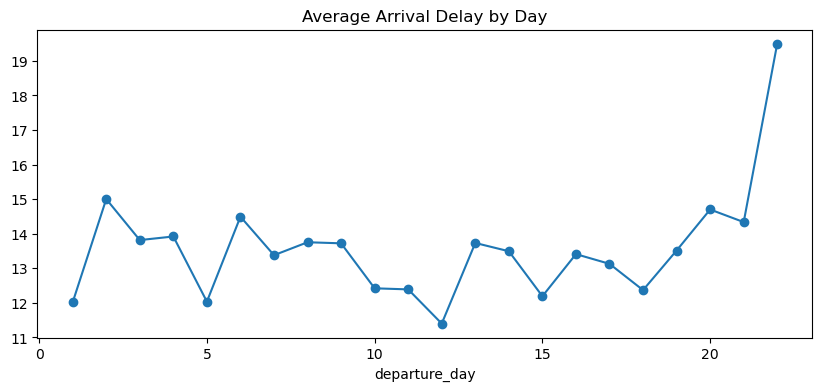

In [84]:
df.groupby("departure_day")["actual_arrival_delay_min"].mean().plot(
    figsize=(10, 4),
    marker="o",
    title="Average Arrival Delay by Day"
)


In [85]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

importance_df

,Feature,Importance
5,temperature_C,2.996171e-02
2,origin_station,2.800591e-02
16,departure_hour,2.237242e-02
10,event_attendance_est,2.085828e-02
3,destination_station,1.708261e-02
0,transport_type,1.159977e-02
1,route_id,8.040164e-03
11,traffic_congestion_index,4.953864e-03
20,rush_hour_category,4.357023e-03
8,precipitation_mm,2.003565e-03


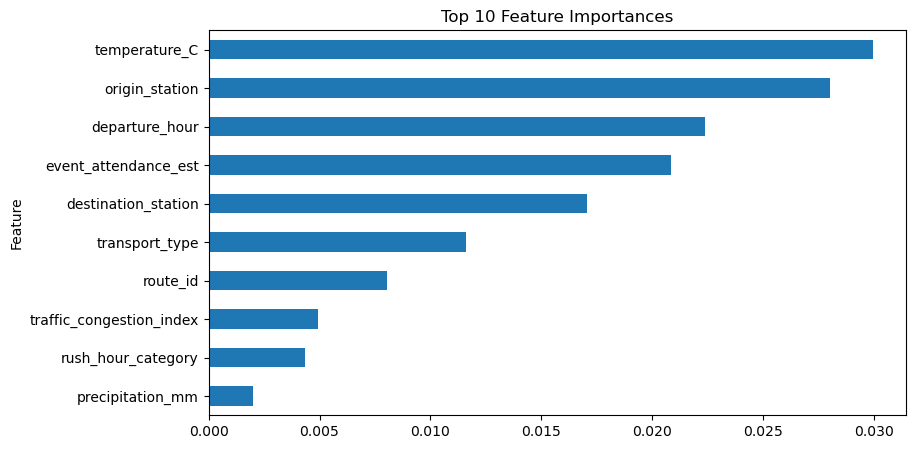

In [86]:
importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(9, 5),
    legend=False,
    title="Top 10 Feature Importances"
)

plt.gca().invert_yaxis()
plt.show()

In [87]:
import matplotlib.pyplot as plt

In [88]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

gb_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_features)
])

gb_model = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

print("Gradient Boosting MAE:",
      round(mean_absolute_error(y_test, gb_pred), 3))
print("Gradient Boosting R2:",
      round(r2_score(y_test, gb_pred), 3))

Gradient Boosting MAE: 8.314
Gradient Boosting R2: -0.068


In [89]:
df[["date", "actual_arrival_delay_min"]].head(15)

,date,actual_arrival_delay_min
0,2023-01-01,3
1,2023-01-01,9
2,2023-01-01,0
3,2023-01-01,10
4,2023-01-01,14
5,2023-01-01,4
6,2023-01-01,28
7,2023-01-01,23
8,2023-01-01,19
9,2023-01-01,3


In [90]:
daily_delay = df.groupby("date")["actual_arrival_delay_min"].agg(
    ["mean", "std", "count"]
)

display(daily_delay.head(10))
print("Number of unique dates:", df["date"].nunique())

,mean,std,count
date,,,
2023-01-01,12.013158,9.439623,76
2023-01-02,15.000000,8.717798,96
2023-01-03,13.812500,8.879678,96
2023-01-04,13.916667,8.702893,96
2023-01-05,12.031250,9.399276,96
2023-01-06,14.489583,9.340342,96
2023-01-07,13.375000,9.692374,96
2023-01-08,13.750000,8.788749,96
2023-01-09,13.718750,9.556153,96


Number of unique dates: 22


In [91]:
print(
    df[["actual_departure_delay_min", "actual_arrival_delay_min"]]
    .corr()
)

                            actual_departure_delay_min  \
actual_departure_delay_min                    1.000000   
actual_arrival_delay_min                     -0.007161   

                            actual_arrival_delay_min  
actual_departure_delay_min                 -0.007161  
actual_arrival_delay_min                    1.000000  


In [92]:
df["scheduled_duration_min"] = (
    df["scheduled_arrival"] - df["scheduled_departure"]
).dt.total_seconds() / 60

print(
    df[["scheduled_duration_min", "actual_arrival_delay_min"]]
    .corr()
)


                          scheduled_duration_min  actual_arrival_delay_min
scheduled_duration_min                  1.000000                  0.035779
actual_arrival_delay_min                0.035779                  1.000000


In [93]:
df.groupby("departure_hour")["actual_arrival_delay_min"].agg(
    ["mean", "std", "count"]
).round(2)

,mean,std,count
departure_hour,,,
0,12.05,8.60,84
1,14.50,9.48,80
2,14.66,8.55,80
3,14.52,10.03,80
4,11.20,8.79,80
5,12.95,9.49,84
6,11.87,10.16,84
7,13.88,9.06,84
8,14.39,8.84,84


In [94]:
print(
    df["actual_arrival_delay_min"]
    .value_counts()
    .sort_index()
)

actual_arrival_delay_min
-3     55
-2     61
-1     49
 0     55
 1     50
 2     57
 3     55
 4     62
 5     57
 6     58
 7     49
 8     45
 9     65
 10    76
 11    84
 12    64
 13    66
 14    67
 15    62
 16    69
 17    66
 18    66
 19    64
 20    51
 21    53
 22    58
 23    69
 24    75
 25    56
 26    61
 27    63
 28    65
 29    47
Name: count, dtype: int64


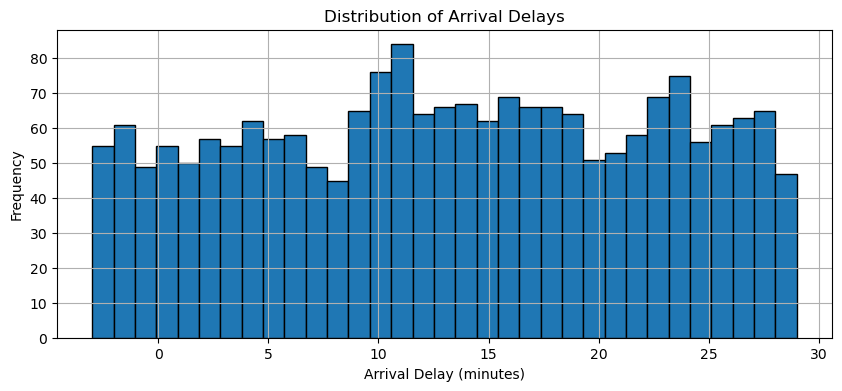

In [95]:
plt.figure(figsize=(10, 4))
df["actual_arrival_delay_min"].hist(bins=33, edgecolor="black")
plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Frequency")
plt.show()

In [96]:
from sklearn.feature_selection import mutual_info_regression

X_mi = X.copy()

for col in categorical_features:
    X_mi[col] = X_mi[col].astype("category").cat.codes

mi_scores = mutual_info_regression(
    X_mi, y, random_state=42
)

mi_df = pd.DataFrame({
    "Feature": X_mi.columns,
    "Mutual Information": mi_scores
}).sort_values("Mutual Information", ascending=False)

display(mi_df)

,Feature,Mutual Information
10,event_attendance_est,0.027924
2,origin_station,0.013707
17,departure_day,0.010637
6,humidity_percent,0.010564
12,holiday,0.000362
13,peak_hour,0.000037
19,is_weekend,0.000000
18,departure_month,0.000000
16,departure_hour,0.000000
15,season,0.000000


In [97]:
from sklearn.utils import shuffle

y_shuffled = shuffle(y, random_state=42)

print("Original target mean:", round(y.mean(), 3))
print("Shuffled target mean:", round(y_shuffled.mean(), 3))
print("Original target std:", round(y.std(), 3))
print("Shuffled target std:", round(y_shuffled.std(), 3))

Original target mean: 13.318
Shuffled target mean: 13.318
Original target std: 9.29
Shuffled target std: 9.29


In [104]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error

shuffled_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

In [105]:
shuffled_y_train = y_train.sample(frac=1, random_state=42).reset_index(drop=True)

shuffled_model.fit(X_train, shuffled_y_train)

shuffled_pred = shuffled_model.predict(X_test)

In [106]:
print("Real model MAE:",
      round(mean_absolute_error(y_test, y_pred_rf), 3))

print("Shuffled model MAE:",
      round(mean_absolute_error(y_test, shuffled_pred), 3))

Real model MAE: 8.237
Shuffled model MAE: 8.17


In [109]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [110]:
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [111]:
xgb_pred = xgb_model.predict(X_test)

In [112]:
results = pd.DataFrame({
    "Model": [
        "Mean Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, xgb_pred),
        mean_absolute_error(y_test, gb_pred)
    ]
})

results = results.sort_values("MAE")
display(results.round(3))

,Model,MAE
0,Mean Baseline,8.212
2,Random Forest,8.237
3,XGBoost,8.263
4,Gradient Boosting,8.314
1,Linear Regression,8.418


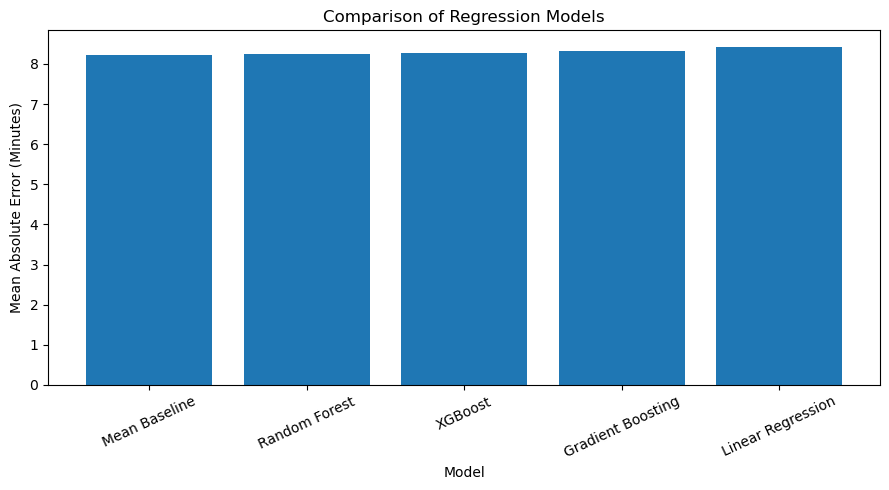

In [113]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["MAE"])
plt.title("Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (Minutes)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [114]:
results.to_csv("model_comparison_results.csv", index=False)

In [115]:
print("FINAL MODEL EVALUATION")
print("----------------------")
print("Best model:", results.iloc[0]["Model"])
print("Best MAE:", round(results.iloc[0]["MAE"], 3), "minutes")
print("Test records:", len(y_test))
print("Training records:", len(y_train))

FINAL MODEL EVALUATION
----------------------
Best model: Mean Baseline
Best MAE: 8.212 minutes
Test records: 400
Training records: 1600


In [116]:
conclusion = """
PROJECT CONCLUSION

The project focused on predicting public transport arrival delays
using weather, traffic, event and transport-related features.

A dataset containing 2,000 records and 24 original columns was
used. Data cleaning, exploratory data analysis and feature
engineering were performed.

Four regression models were evaluated:
Linear Regression, Random Forest, XGBoost and Gradient Boosting.

The Mean Baseline achieved the lowest MAE of 8.212 minutes.
None of the trained machine learning models outperformed it.

The results indicate weak predictive relationships between the
available features and arrival delay.

Future improvements could include larger real-world datasets,
historical delay information, route distance and real-time traffic.

The project demonstrates the complete machine learning workflow
and highlights the importance of data quality and feature relevance.
"""

print(conclusion)


PROJECT CONCLUSION

The project focused on predicting public transport arrival delays
using weather, traffic, event and transport-related features.

A dataset containing 2,000 records and 24 original columns was
used. Data cleaning, exploratory data analysis and feature
engineering were performed.

Four regression models were evaluated:
Linear Regression, Random Forest, XGBoost and Gradient Boosting.

The Mean Baseline achieved the lowest MAE of 8.212 minutes.
None of the trained machine learning models outperformed it.

The results indicate weak predictive relationships between the
available features and arrival delay.

Future improvements could include larger real-world datasets,
historical delay information, route distance and real-time traffic.

The project demonstrates the complete machine learning workflow
and highlights the importance of data quality and feature relevance.



In [117]:
with open("project_conclusion.txt", "w") as file:
    file.write(conclusion)

print("Conclusion saved!")

Conclusion saved!


In [118]:
import os

for file in os.listdir():
    print(file)

.ipynb_checkpoints
model_comparison.png
model_comparison_results.csv
project_conclusion.txt
public_transport_delays.csv
public_transport_delays_cleaned.csv
Untitled Folder
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb
Untitled3.ipynb
